In [1]:
!pip install scanpy pandas matplotlib


# Task 1 - Read the Visium Data


In [2]:
import scanpy as sc
import pandas as pd

# 1. Read raw Visium data
path = "visium_sample/"
adata = sc.read_visium(path=path, count_file='filtered_feature_bc_matrix.h5')
adata.var_names_make_unique()

# 2. Load the metadata
metadata = pd.read_csv("visium_sample/metadata.tsv", sep='\t', index_col=0)

# 3. Add the column to the object
adata.obs['layer_guess_reordered'] = metadata['layer_guess_reordered']

# 4. Load the processed file
adata_processed = sc.read_h5ad("visium_sample/151671_visium_processed.h5ad")

# 5. THE FIX: Reorder the data to match the spot order
# This ensures that barcode 'A' in the object is compared to barcode 'A' in given sample
adata = adata[adata_processed.obs_names].copy()

# 6. Final Verification
# .astype(str) was used to ignore technical data type differences
match_check = adata.obs['layer_guess_reordered'].astype(str).equals(
    adata_processed.obs['annotation'].astype(str)
)

print(f"Task 1 Success - Metadata Match: {match_check}")
print(adata)


C:\Users\User\AppData\Local\Temp\ipykernel_26608\4067619952.py:6: FutureWarning: Use `squidpy.read.visium` instead.
  adata = sc.read_visium(path=path, count_file='filtered_feature_bc_matrix.h5')
C:\Users\User\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Task 1 Success - Metadata Match: True
AnnData object with n_obs × n_vars = 1808 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'layer_guess_reordered'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


# Task 2 - Perform Clustering and visualize

In [3]:
# Normalize and Log-transform the data
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Find Highly Variable Genes (Feature Selection)
sc.pp.highly_variable_genes(adata, subset=True)

# Scale the data for PCA
sc.pp.scale(adata, max_value=10)


C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [4]:
!pip install leidenalg igraph

C:\Users\User\AppData\Local\Temp\ipykernel_26608\7093489.py:9: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, img_key="hires", color=['leiden_clusters', 'layer_guess_reordered'])


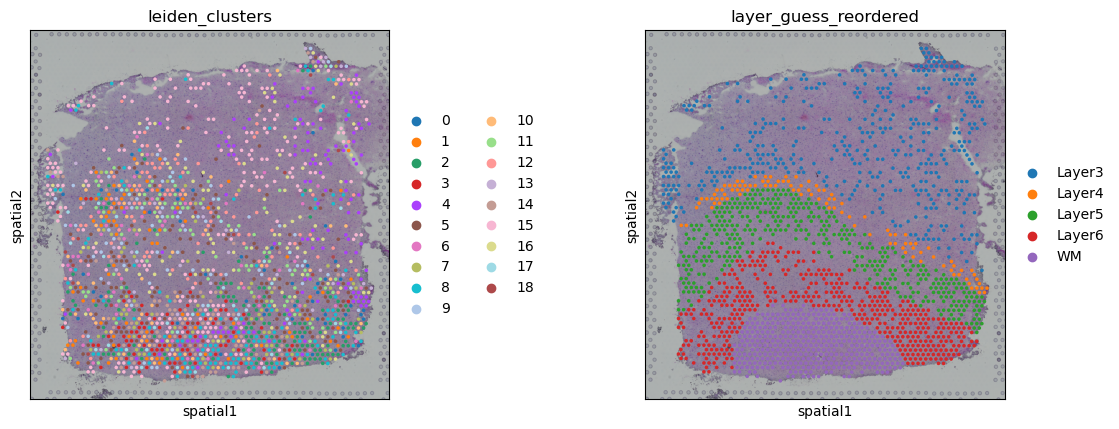

--- Task 2 Evaluation Metrics ---
Adjusted Rand Index (ARI): 0.0761
Normalized Mutual Info (NMI): 0.1277


In [5]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Run the Clustering
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=40)
sc.tl.leiden(adata, resolution=1.4, key_added='leiden_clusters', flavor='igraph', n_iterations=2)

# 2. Show the Plot first
sc.pl.spatial(adata, img_key="hires", color=['leiden_clusters', 'layer_guess_reordered'])

# 3. Calculate and Print the Metrics immediately after
ground_truth = adata.obs['layer_guess_reordered'].astype(str)
predicted = adata.obs['leiden_clusters'].astype(str)

ari_score = adjusted_rand_score(ground_truth, predicted)
nmi_score = normalized_mutual_info_score(ground_truth, predicted)

print(f"--- Task 2 Evaluation Metrics ---")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")
print(f"Normalized Mutual Info (NMI): {nmi_score:.4f}")


C:\Users\User\AppData\Local\Temp\ipykernel_26608\222546432.py:10: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, img_key="hires", color=['spatial_leiden', 'layer_guess_reordered'])


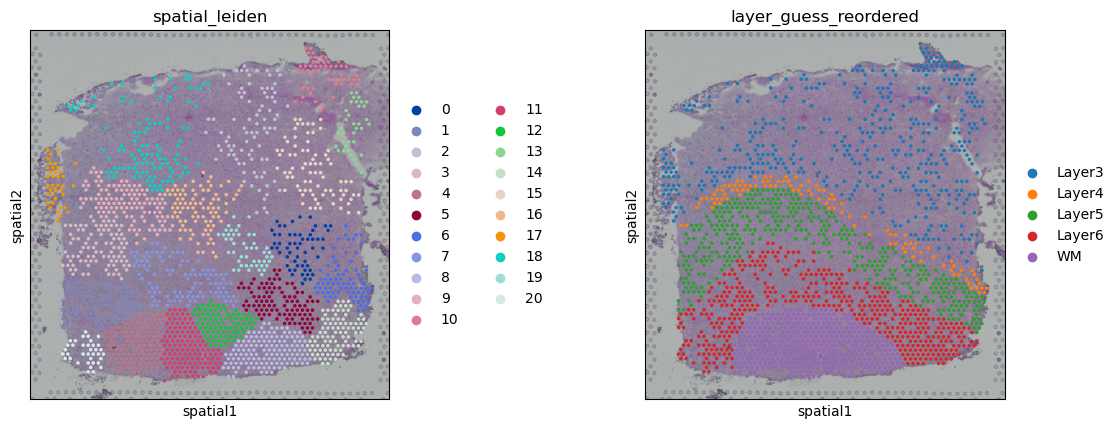

--- Improved Spatial Metrics ---
Adjusted Rand Index (ARI): 0.2008
Normalized Mutual Info (NMI): 0.4752


In [6]:
# Task 2: Spatial Clustering (Corrected)
# 1. Compute neighbors using only the 2D spatial coordinates
sc.pp.neighbors(adata, n_neighbors=15, use_rep='spatial')

# 2. Re-run Leiden clustering 
# New name 'spatial_leiden' to keep it separate from previous run
sc.tl.leiden(adata, resolution=0.8, key_added='spatial_leiden', flavor='igraph')

# 3. Plot the results
sc.pl.spatial(adata, img_key="hires", color=['spatial_leiden', 'layer_guess_reordered'])

# 4. Calculate the improved metrics
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_spatial = adjusted_rand_score(adata.obs['layer_guess_reordered'], adata.obs['spatial_leiden'])
nmi_spatial = normalized_mutual_info_score(adata.obs['layer_guess_reordered'], adata.obs['spatial_leiden'])

print(f"--- Improved Spatial Metrics ---")
print(f"Adjusted Rand Index (ARI): {ari_spatial:.4f}")
print(f"Normalized Mutual Info (NMI): {nmi_spatial:.4f}")


# Task 3 - Perform Clustering and visualize

In [7]:
import scanpy as sc
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def get_benchmarks(folder_path):
    print(f"--- Processing {folder_path} ---")
    # 1. Load the data
    adata_raw = sc.read_visium(folder_path, count_file='filtered_feature_bc_matrix.h5')
    metadata = pd.read_csv(f"{folder_path}/metadata.tsv", sep='\t', index_col=0)
    
    # 2. Map the labels
    label = 'layer_guess_reordered' if 'layer_guess_reordered' in metadata.columns else 'annotation'
    adata_raw.obs['gt'] = metadata[label]
    adata_raw.var_names_make_unique()

    # 3. Benchmark Loop
    results = {}
    for mode, n_genes in [("After PCA", None), ("Top 2000", 2000), ("Top 5000", 5000)]:
        temp = adata_raw.copy()
        sc.pp.normalize_total(temp, target_sum=1e4)
        sc.pp.log1p(temp)
        if n_genes:
            sc.pp.highly_variable_genes(temp, n_top_genes=n_genes, subset=True)
        sc.pp.scale(temp)
        sc.tl.pca(temp)
        sc.pp.neighbors(temp)
        sc.tl.leiden(temp, resolution=0.8)
        
        # Calculate Scores
        ari = adjusted_rand_score(temp.obs['gt'].astype(str), temp.obs['leiden'].astype(str))
        nmi = normalized_mutual_info_score(temp.obs['gt'].astype(str), temp.obs['leiden'].astype(str))
        results[mode] = (f"ARI: {ari:.3f}", f"NMI: {nmi:.3f}")
        
        # 4. Requirement: Produce clustering image for the "After PCA" case
        if mode == "After PCA":
            sc.pl.spatial(temp, img_key="hires", color='leiden', title=f"Sample: {folder_path}")
            
    return results


--- Processing visium_sample ---


C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:8: FutureWarning: Use `squidpy.read.visium` instead.
  adata_raw = sc.read_visium(folder_path, count_file='filtered_feature_bc_matrix.h5')
C:\Users\User\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False

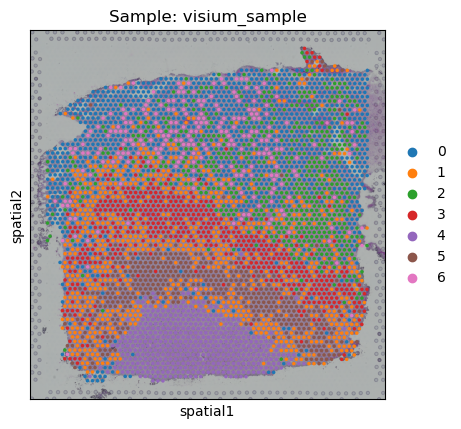

C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(temp, resolution=0.8)
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the

{'After PCA': ('ARI: 0.315', 'NMI: 0.436'), 'Top 2000': ('ARI: 0.206', 'NMI: 0.195'), 'Top 5000': ('ARI: 0.207', 'NMI: 0.255')}


In [8]:
# This actually starts the calculation for your first row
res_151671 = get_benchmarks("visium_sample")
print(res_151671)


--- Processing 151507 ---


C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:8: FutureWarning: Use `squidpy.read.visium` instead.
  adata_raw = sc.read_visium(folder_path, count_file='filtered_feature_bc_matrix.h5')
C:\Users\User\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False

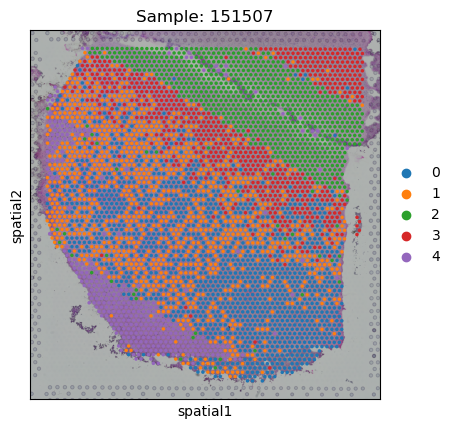

C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(temp, resolution=0.8)
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the

{'After PCA': ('ARI: 0.302', 'NMI: 0.416'), 'Top 2000': ('ARI: 0.228', 'NMI: 0.250'), 'Top 5000': ('ARI: 0.262', 'NMI: 0.312')}


In [9]:
# This will generate the images and the numbers for your 151507 table row
res_151507 = get_benchmarks("151507")
print(res_151507)


--- Processing 151508 ---


C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:8: FutureWarning: Use `squidpy.read.visium` instead.
  adata_raw = sc.read_visium(folder_path, count_file='filtered_feature_bc_matrix.h5')
C:\Users\User\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False

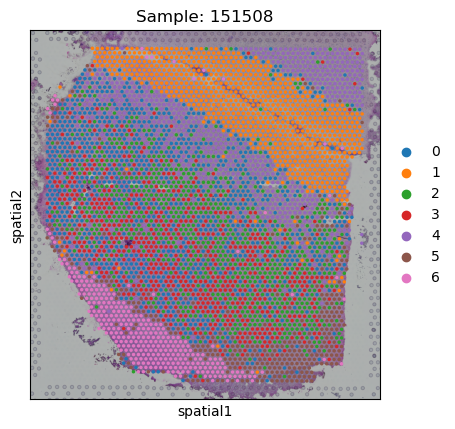

C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(temp, resolution=0.8)
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the

{'After PCA': ('ARI: 0.299', 'NMI: 0.377'), 'Top 2000': ('ARI: 0.146', 'NMI: 0.194'), 'Top 5000': ('ARI: 0.191', 'NMI: 0.240')}


In [10]:
# Generate images and numbers for the 151508 table row
res_151508 = get_benchmarks("151508")
print(res_151508)


--- Processing 151509 ---


C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:8: FutureWarning: Use `squidpy.read.visium` instead.
  adata_raw = sc.read_visium(folder_path, count_file='filtered_feature_bc_matrix.h5')
C:\Users\User\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False

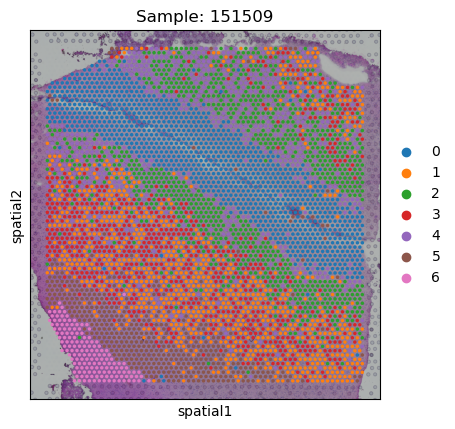

C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(temp, resolution=0.8)
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the

{'After PCA': ('ARI: 0.374', 'NMI: 0.486'), 'Top 2000': ('ARI: 0.126', 'NMI: 0.223'), 'Top 5000': ('ARI: 0.179', 'NMI: 0.281')}


In [11]:
# Results for 151509
res_151509 = get_benchmarks("151509")
print(res_151509)


--- Processing 151510 ---


C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:8: FutureWarning: Use `squidpy.read.visium` instead.
  adata_raw = sc.read_visium(folder_path, count_file='filtered_feature_bc_matrix.h5')
C:\Users\User\anaconda3\Lib\site-packages\anndata\_core\anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False

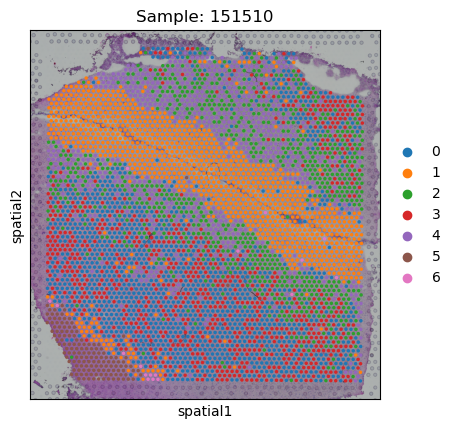

C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(temp, resolution=0.8)
C:\Users\User\anaconda3\Lib\functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\User\AppData\Local\Temp\ipykernel_26608\3430164189.py:27: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the

{'After PCA': ('ARI: 0.298', 'NMI: 0.377'), 'Top 2000': ('ARI: 0.128', 'NMI: 0.196'), 'Top 5000': ('ARI: 0.158', 'NMI: 0.223')}


In [12]:
# Results for 151510
res_151510 = get_benchmarks("151510")
print(res_151510)
